# Input pipeline smoke test

Checks that the tf.data pipeline in `gold_dl.data_pipeline` delivers correct data, before any real modelling:

1. batch shapes, data types and label values for the training, validation and test sets;
2. each window is exactly the 60 rows of the feature table that end at minute *t*, and each label is the one stored for that minute;
3. a minimal Keras model (Flatten + one Dense layer) trains for 300 steps and its training loss decreases.

The point is to prove the pipeline works, not to predict well. Requirements: the training environment, `pip install -e .`, and `model_data/model_arrays.npz` built by `scripts/export_model_arrays.py`. The notebook writes no files.

In [1]:
import time

import keras
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf

from gold_dl.config import CFG
from gold_dl.data_pipeline import BATCH, L, SEED, load_arrays, make_dataset, masked_sparse_ce

keras.utils.set_random_seed(SEED)   # Python, NumPy and TensorFlow seeds
print("TensorFlow", tf.__version__, "| devices:", [d.device_type for d in tf.config.list_physical_devices()])
print(f"lookback L = {L}, batch size = {BATCH}, seed = {SEED}")

TensorFlow 2.16.2 | devices: ['CPU', 'GPU']
lookback L = 60, batch size = 256, seed = 42


## 1. Load the arrays and build the three pipelines

`X_all` is the whole standardised feature table (one row per minute, 33 features). A sample is only a row index *t* (the last row of its window) and the 6 labels; the window is cut from `X_all` inside the pipeline. Only the training set is shuffled.

In [2]:
arr = load_arrays()
names, heads = list(arr["feature_names"]), list(arr["head_names"])
print("X_all", arr["X_all"].shape, arr["X_all"].dtype, f"{arr['X_all'].nbytes / 1e6:.1f} MB")
print("heads:", heads)
ds = {s: make_dataset(arr, s) for s in ["train", "val", "test"]}
for s in ds:
    n = len(arr[f"end_{s}"])
    print(f"{s:5s}: {n:>7,} samples, {int(np.ceil(n / BATCH)):>4} batches per pass")

X_all (352187, 33) float32 46.5 MB
heads: ['long_H15', 'long_H30', 'long_H60', 'short_H15', 'short_H30', 'short_H60']


train: 231,516 samples,  905 batches per pass
val  :  48,936 samples,  192 batches per pass
test :  52,170 samples,  204 batches per pass


2026-11-01 21:13:36.956558: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M4 Pro
2026-11-01 21:13:36.956613: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 24.00 GB
2026-11-01 21:13:36.956620: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 8.88 GB
2026-11-01 21:13:36.956665: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2026-11-01 21:13:36.956677: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


## 2. Batch shapes, types and label values

For one batch of each set, check the shapes and types, and that the labels only take the expected values: 0 = take-profit first, 1 = stop-loss first, 2 = timeout, −1 = no label (masked in the loss). Then check the batch against the arrays directly: the window must equal rows *t* − 59 … *t* of `X_all`, and the labels must equal the stored labels for those samples.

In [3]:
for s, d in ds.items():
    x, y, t = next(iter(d))
    x, y, t = x.numpy(), y.numpy(), t.numpy()
    print(f"{s:5s}: x {x.shape} {x.dtype} | y {y.shape} {y.dtype} values {sorted(np.unique(y).tolist())} | t {t.shape} {t.dtype}")
    assert x.shape == (BATCH, L, len(names)) and x.dtype == np.float32
    assert y.shape == (BATCH, len(heads)) and set(np.unique(y)) <= {-1, 0, 1, 2}
    assert np.array_equal(x, np.stack([arr["X_all"][i - L + 1:i + 1] for i in t]))
    pos = np.searchsorted(arr[f"end_{s}"], t)
    assert np.array_equal(y, arr[f"y_{s}"][pos])
print("all batch checks passed")

train: x (256, 60, 33) float32 | y (256, 6) int32 values [-1, 0, 1, 2] | t (256,) int64


val  : x (256, 60, 33) float32 | y (256, 6) int32 values [-1, 0, 1, 2] | t (256,) int64
test : x (256, 60, 33) float32 | y (256, 6) int32 values [-1, 0, 1, 2] | t (256,) int64
all batch checks passed


Labels of the first 5 training samples, decoded from the batch itself:

In [4]:
CLS = {0: "TP", 1: "SL", 2: "timeout", -1: "missing"}
x, y, t = next(iter(ds["train"]))
times = arr["time_ns"].astype("datetime64[ns]")
for j in range(5):
    labels = ", ".join(f"{h} {CLS[int(v)]}" for h, v in zip(heads, y[j].numpy()))
    print(f"{str(times[int(t[j])])[:16].replace('T', ' ')} (Beijing time): {labels}")

2026-01-22 01:01 (Beijing time): long_H15 SL, long_H30 SL, long_H60 SL, short_H15 TP, short_H30 TP, short_H60 TP
2026-04-29 08:51 (Beijing time): long_H15 SL, long_H30 SL, long_H60 SL, short_H15 SL, short_H30 TP, short_H60 TP
2025-10-11 00:00 (Beijing time): long_H15 SL, long_H30 SL, long_H60 SL, short_H15 TP, short_H30 TP, short_H60 TP
2026-02-12 22:36 (Beijing time): long_H15 SL, long_H30 SL, long_H60 SL, short_H15 TP, short_H30 TP, short_H60 TP
2026-02-26 09:37 (Beijing time): long_H15 timeout, long_H30 timeout, long_H60 SL, short_H15 timeout, short_H30 timeout, short_H60 TP


## 3. Time for one full pass of the training data through the pipeline

No model, only data delivery. This is far below the time of a training epoch, so the pipeline is not the bottleneck.

In [5]:
t0 = time.perf_counter()
for _ in ds["train"]:
    pass
print(f"one pass of the training set: {time.perf_counter() - t0:.2f} s")

one pass of the training set: 0.32 s


2026-11-01 21:13:37.868404: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


## 4. Smoke test: Flatten + one Dense output layer, 300 steps

The model outputs 6 × 3 logits (6 heads, 3 classes). The loss is the cross-entropy averaged over the labels that are not missing. Two reference levels: guessing uniformly gives ln 3 = 1.099; guessing the training class shares gives their entropy.

In [6]:
STEPS = 300
xy = lambda d: d.map(lambda x, y, t: (x, y))
smoke = keras.Sequential([keras.Input((L, len(names))), keras.layers.Flatten(),
                          keras.layers.Dense(len(heads) * 3), keras.layers.Reshape((len(heads), 3))])
smoke.compile(optimizer=keras.optimizers.Adam(1e-3), loss=masked_sparse_ce)
print(f"{smoke.count_params():,} parameters")

prior = []
for k in range(len(heads)):
    v = arr["y_train"][:, k][arr["y_train"][:, k] >= 0]
    p = np.bincount(v, minlength=3) / len(v)
    prior.append(-(p * np.log(p)).sum())
prior = float(np.mean(prior))

hist = []
cb = keras.callbacks.LambdaCallback(on_train_batch_end=lambda b, logs: hist.append(logs["loss"]))
val_before = smoke.evaluate(xy(ds["val"]).take(50), verbose=0)
smoke.fit(xy(ds["train"]).repeat(), steps_per_epoch=STEPS, epochs=1, callbacks=[cb], verbose=0)
val_after = smoke.evaluate(xy(ds["val"]).take(50), verbose=0)

h = np.array(hist)   # Keras logs the running mean within the epoch; convert back to per-step loss
step_loss = np.r_[h[0], h[1:] * np.arange(2, len(h) + 1) - h[:-1] * np.arange(1, len(h))]
print(f"training loss, first 10 steps: {step_loss[:10].mean():.3f}; last 10 steps: {step_loss[-10:].mean():.3f}")
print(f"validation loss (50 batches): before {val_before:.3f}, after {val_after:.3f}; class-prior guess {prior:.3f}")
assert step_loss[-10:].mean() < step_loss[:10].mean(), "training loss did not decrease"

2026-11-01 21:13:37.974083: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


35,658 parameters


training loss, first 10 steps: 1.295; last 10 steps: 1.059
validation loss (50 batches): before 1.504, after 1.080; class-prior guess 1.066


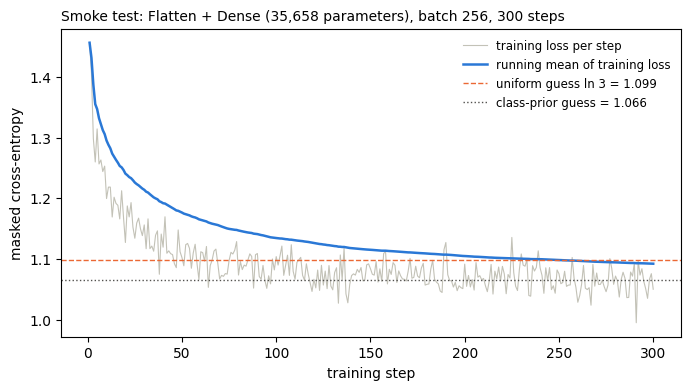

In [7]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(np.arange(1, len(h) + 1), step_loss, color="#c3c2b7", lw=0.8, label="training loss per step")
ax.plot(np.arange(1, len(h) + 1), h, color="#2a78d6", lw=1.8, label="running mean of training loss")
ax.axhline(np.log(3), color="#eb6834", ls="--", lw=1, label="uniform guess ln 3 = 1.099")
ax.axhline(prior, color="#52514e", ls=":", lw=1, label=f"class-prior guess = {prior:.3f}")
ax.set_xlabel("training step")
ax.set_ylabel("masked cross-entropy")
ax.set_title(f"Smoke test: Flatten + Dense ({smoke.count_params():,} parameters), batch {BATCH}, {STEPS} steps", loc="left", fontsize=10)
ax.legend(frameon=False, fontsize=8.5)
plt.show()

## Result

The batches have the expected shapes, types and label values, the windows and labels match the arrays, and the training loss falls within 300 steps (about 1.30 over the first 10 steps, 1.06 over the last 10) to the class-prior level of 1.066, and the validation loss falls from 1.50 to 1.08. A linear model this small mainly learns the class shares in so few steps, which is expected: the smoke test checks the pipeline, not predictive skill.